In [74]:
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt

dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])


# SUBPLOTS

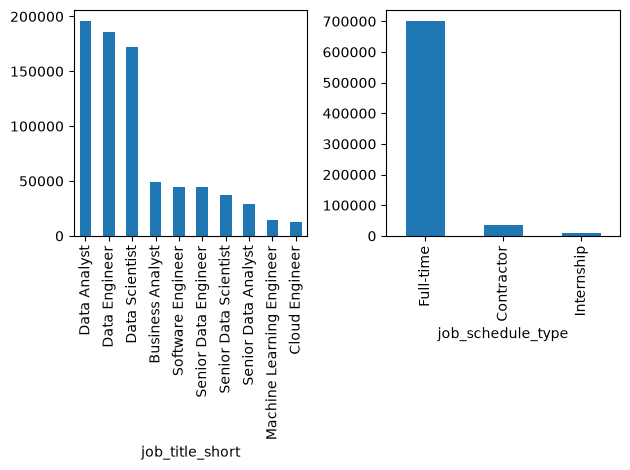

In [75]:
fig, ax=plt.subplots(1,2)

df['job_title_short'].value_counts().plot(kind='bar', ax=ax[0])
df['job_schedule_type'].value_counts().head(3).plot(kind='bar', ax=ax[1])

plt.tight_layout()

In [76]:
df_skills=df.copy()
df_skills = df_skills.explode('job_skills')
skills_count=df_skills.groupby(['job_skills', 'job_title_short']).size()


In [77]:
df_skills_count =skills_count.reset_index(name = 'skills_count')
df_skills_count.sort_values(by='skills_count', ascending=False, inplace=True)
df_skills_count

,job_skills,job_title_short,skills_count
16110,['excel'],Data Analyst,8095
208186,['sql'],Data Analyst,4997
116092,['python'],Data Scientist,4659
146457,"['sql', 'excel']",Data Analyst,3020
16108,['excel'],Business Analyst,2443
...,...,...,...
215206,['xamarin'],Software Engineer,1
215205,"['xamarin', 'node', 'git', 'svn']",Software Engineer,1
215204,"['xamarin', 'ionic', 'windows']",Software Engineer,1
215203,['wsl'],Data Scientist,1


In [78]:
job_titles=['Data Analyst','Data Scientist', 'Data Engineer']

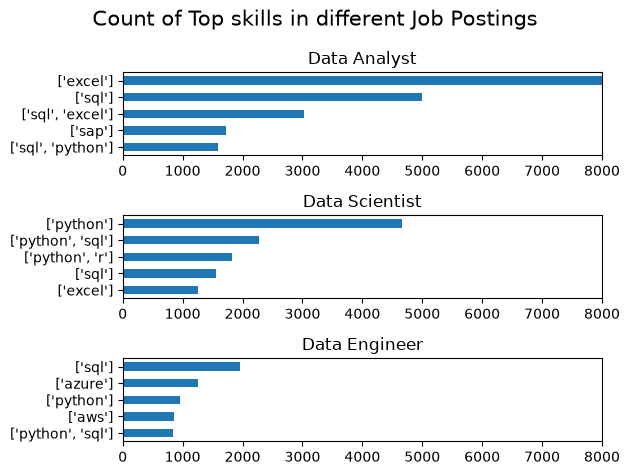

In [79]:
fig, ax=plt.subplots(3,1)

for i, job_title in enumerate(job_titles):
    df_plot=df_skills_count[df_skills_count['job_title_short'] == job_title].head(5)
    df_plot.plot(kind='barh', x='job_skills', y='skills_count', ax=ax[i], title=job_title)
    ax[i].invert_yaxis()
    ax[i].set_ylabel('')
    ax[i].legend().set_visible(False)
    ax[i].set_xlim(0,8000)

fig.suptitle('Count of Top skills in different Job Postings', fontsize=15)
fig.tight_layout()

# PIE CHART

Text(0, 0.5, ' ')

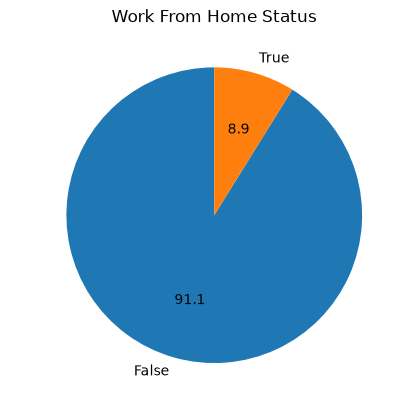

In [84]:
df['job_work_from_home'].value_counts().plot(kind='pie', startangle = 90, autopct='%1.1f')
plt.title('Work From Home Status')
plt.ylabel(' ')

In [87]:
df[['job_work_from_home', 'job_no_degree_mention','job_health_insurance']]

,job_work_from_home,job_no_degree_mention,job_health_insurance
0,False,False,False
1,False,False,False
2,False,False,False
3,False,True,False
4,False,False,False
...,...,...,...
785736,False,False,False
785737,False,False,False
785738,False,False,False
785739,False,False,False


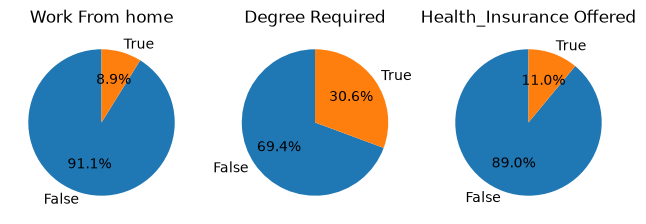

In [101]:
import numpy as np
fig, ax=plt.subplots(1,3)

dict_column= {
    'job_work_from_home' : 'Work From home',
    'job_no_degree_mention' : 'Degree Required',
    'job_health_insurance' : 'Health_Insurance Offered'
}
for i, (column, title) in enumerate(dict_column.items()):
    ax[i].pie(df[column].value_counts(), startangle=90, autopct='%1.1f%%', labels=['False', 'True'])
    ax[i].set_title(title)
plt.tight_layout()
plt.show()
